In [19]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/henavajov/conll2003/CoNLL-2003/CoNLL-2003/dev.txt
/kaggle/input/datasets/henavajov/conll2003/CoNLL-2003/CoNLL-2003/test.txt
/kaggle/input/datasets/henavajov/conll2003/CoNLL-2003/CoNLL-2003/train.txt


# 
dữ liệu được biểu diễn như nào
- Thay vì lưu cả câu và 1 nhãn duy nhất, CoNLL-2003 gán nhãn cho từng từ một
- Brack -> B-Per
- Obama -> I-per
- visited -> O
- Paris -> B-Loc
- . -> O
Một thực thể có thể có nhiều từ, vì vậy chúng ta cần 1 cơ chế xác định từ nào bắt đầu và từ nào tiếp tục thực thể đó. Đây chính là lý do xuất hiện BIO Tagging

## Biotagging
- BIO là 1 quy tắc gán nhãn được sử dụng trong bài toán NER để xác định vị trí của từng từ trong một thực thể
- BIO gồm ba nhãn: B-X, I-X và O: lần lượt là beginning, inside và outside của thực thể

## 1 số trường hợp cần nhớ
- Thực thể chỉ có 1 từ: John: B-per và works - 0
- Thực thể có nhiều từ: Ho-B-Loc, Chi-I-Loc, Minh-I-LOc, city-I-Loc => từ đầu tiên sử dụng BLOc các từ tiếp theo là ILOC
- hai thực thể cùng loại đứng cạnh nhau: John-B-Per và Marry-B-Per

## Label Alignment: Căn chỉnh nhãn
| Bước | Ý nghĩa |
|---|---|
| Original Words | Các từ ban đầu trong câu |
| Word-level Labels | Nhãn NER được gán cho từng từ |
| Tokenizer | Chia từ thành các token/subword |
| Subword Tokens | Các token được tạo ra sau Tokenization |
| Label Alignment | Điều chỉnh nhãn tương ứng với token |
| Aligned Labels | Bộ nhãn khớp với đầu ra của Tokenizer |
| Transformer Training | Huấn luyện mô hình với các nhãn đã căn chỉnh |

## Alignment Strategies - Các chiến lược căn chỉnh nhãn
Strategy A - chỉ gán nhãn cho subword đầu tiên
Strategy B - Lan truyền nhãn (Label Propagation)
Strategy C - Sử dụng cơ chế Alignment của Pipeline

# 13. Baseline

In [20]:
from pathlib import Path


DATA_DIR = Path(
    "/kaggle/input/datasets/henavajov/conll2003/"
    "CoNLL-2003/CoNLL-2003"
)
TRAIN_PATH = DATA_DIR / "train.txt"
DEV_PATH = DATA_DIR / "dev.txt"
TEST_PATH = DATA_DIR / "test.txt"

In [21]:
def read_conll(path):
    sentences = []
    sentence = []

    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()

            if not line:
                if sentence:
                    sentences.append(sentence)
                    sentence = []
                continue

            if line.startswith("-DOCSTART-"):
                continue

            columns = line.split()

            if len(columns) < 2:
                continue

            word = columns[0]
            label = columns[-1]

            sentence.append((word, label))

    if sentence:
        sentences.append(sentence)

    return sentences

In [22]:
train_sentences = read_conll(TRAIN_PATH)
dev_sentences = read_conll(DEV_PATH)
test_sentences = read_conll(TEST_PATH)

print("Train:", len(train_sentences))
print("Dev:", len(dev_sentences))
print("Test:", len(test_sentences))

Train: 14041
Dev: 3250
Test: 3453


In [23]:
for word, label in train_sentences[0]:
    print(f"{word:15s} {label}")

EU              B-ORG
rejects         O
German          B-MISC
call            O
to              O
boycott         O
British         B-MISC
lamb            O
.               O


In [24]:
def extract_features(sentence, index):
    word = sentence[index][0]

    prev_word = (
        sentence[index - 1][0]
        if index > 0
        else "<BOS>"
    )

    next_word = (
        sentence[index + 1][0]
        if index < len(sentence) - 1
        else "<EOS>"
    )

    features = {
        "word": word,
        "lower": word.lower(),
        "prefix_1": word[:1],
        "prefix_2": word[:2],
        "prefix_3": word[:3],
        "suffix_1": word[-1:],
        "suffix_2": word[-2:],
        "suffix_3": word[-3:],
        "is_upper": word.isupper(),
        "is_title": word.istitle(),
        "is_lower": word.islower(),
        "is_digit": word.isdigit(),
        "has_digit": any(
            char.isdigit() for char in word
        ),
        "has_hyphen": "-" in word,
        "prev_word": prev_word.lower(),
        "next_word": next_word.lower(),
    }

    return features

In [25]:
from sklearn.feature_extraction import DictVectorizer


def prepare_features(sentences):
    X = []
    y = []

    for sentence in sentences:
        for index, (word, label) in enumerate(sentence):
            features = extract_features(
                sentence,
                index
            )

            X.append(features)
            y.append(label)

    return X, y

In [26]:
X_train, y_train = prepare_features(
    train_sentences
)

X_dev, y_dev = prepare_features(
    dev_sentences
)

X_test, y_test = prepare_features(
    test_sentences
)

In [27]:
from sklearn.feature_extraction import DictVectorizer


vectorizer = DictVectorizer()

X_train_vec = vectorizer.fit_transform(X_train)

X_dev_vec = vectorizer.transform(X_dev)

X_test_vec = vectorizer.transform(X_test)

In [28]:
print("Train shape:", X_train_vec.shape)
print("Dev shape:", X_dev_vec.shape)
print("Test shape:", X_test_vec.shape)

Train shape: (203621, 99395)
Dev shape: (51362, 99395)
Test shape: (46435, 99395)


In [29]:
from sklearn.linear_model import LogisticRegression


baseline_model = LogisticRegression(
    max_iter=1000,
    solver="lbfgs"
)

baseline_model.fit(
    X_train_vec,
    y_train
)

LogisticRegression(max_iter=1000)

In [30]:
!pip install -q seqeval

In [31]:
def get_true_labels(sentences):
    return [
        [label for _, label in sentence]
        for sentence in sentences
    ]

In [32]:
from seqeval.metrics import (
    classification_report,
    f1_score,
    precision_score,
    recall_score
)


def predict_sentences(sentences, model, vectorizer):
    predictions = []

    for sentence in sentences:
        features = [
            extract_features(sentence, index)
            for index in range(len(sentence))
        ]

        X = vectorizer.transform(features)
        pred = model.predict(X)

        predictions.append(pred.tolist())

    return predictions

In [33]:
y_true_test = get_true_labels(test_sentences)

y_pred_test = predict_sentences(
    test_sentences,
    baseline_model,
    vectorizer
)

print(
    classification_report(
        y_true_test,
        y_pred_test
    )
)

              precision    recall  f1-score   support

         LOC       0.78      0.80      0.79      1668
        MISC       0.71      0.76      0.74       702
         ORG       0.61      0.65      0.63      1661
         PER       0.66      0.79      0.72      1617

   micro avg       0.69      0.75      0.72      5648
   macro avg       0.69      0.75      0.72      5648
weighted avg       0.69      0.75      0.72      5648



# 14. Transformer Token Classification

In [34]:
!pip install -q transformers datasets accelerate seqeval

In [35]:
labels = sorted({
    label
    for sentence in train_sentences
    for _, label in sentence
})

label2id = {
    label: idx
    for idx, label in enumerate(labels)
}

id2label = {
    idx: label
    for label, idx in label2id.items()
}

num_labels = len(labels)

print("Labels:", labels)
print("Number of labels:", num_labels)

Labels: ['B-LOC', 'B-MISC', 'B-ORG', 'B-PER', 'I-LOC', 'I-MISC', 'I-ORG', 'I-PER', 'O']
Number of labels: 9


In [36]:
from transformers import AutoTokenizer


MODEL_NAME = "bert-base-cased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

In [37]:
from datasets import Dataset


def convert_to_dataset(sentences):
    data = {
        "words": [],
        "ner_tags": []
    }

    for sentence in sentences:
        words = [
            word
            for word, _ in sentence
        ]

        ner_tags = [
            label2id[label]
            for _, label in sentence
        ]

        data["words"].append(words)
        data["ner_tags"].append(ner_tags)

    return Dataset.from_dict(data)

In [38]:
train_dataset = convert_to_dataset(
    train_sentences
)

dev_dataset = convert_to_dataset(
    dev_sentences
)

test_dataset = convert_to_dataset(
    test_sentences
)

In [39]:
print(train_dataset[0])

{'words': ['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.'], 'ner_tags': [2, 8, 1, 8, 8, 8, 1, 8, 8]}


In [40]:
def tokenize_and_align_labels(examples):
    tokenized_inputs = tokenizer(
        examples["words"],
        is_split_into_words=True,
        truncation=True,
        max_length=256
    )

    aligned_labels = []

    for batch_idx, word_labels in enumerate(
        examples["ner_tags"]
    ):
        word_ids = tokenized_inputs.word_ids(
            batch_index=batch_idx
        )

        previous_word_id = None
        label_ids = []

        for word_id in word_ids:
            if word_id is None:
                label_ids.append(-100)

            elif word_id != previous_word_id:
                label_ids.append(
                    word_labels[word_id]
                )

            else:
                label_ids.append(-100)

            previous_word_id = word_id

        aligned_labels.append(label_ids)

    tokenized_inputs["labels"] = aligned_labels

    return tokenized_inputs

In [41]:
train_tokenized = train_dataset.map(
    tokenize_and_align_labels,
    batched=True
)

dev_tokenized = dev_dataset.map(
    tokenize_and_align_labels,
    batched=True
)

test_tokenized = test_dataset.map(
    tokenize_and_align_labels,
    batched=True
)

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

In [42]:
sample = train_tokenized[0]

tokens = tokenizer.convert_ids_to_tokens(
    sample["input_ids"]
)

for token, label_id in zip(
    tokens,
    sample["labels"]
):
    label = (
        "IGNORE"
        if label_id == -100
        else id2label[label_id]
    )

    print(f"{token:15s} {label}")

[CLS]           IGNORE
EU              B-ORG
rejects         O
German          B-MISC
call            O
to              O
boycott         O
British         B-MISC
la              O
##mb            IGNORE
.               O
[SEP]           IGNORE


In [43]:
from transformers import (
    AutoModelForTokenClassification
)


model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly i

In [44]:
from transformers import (
    DataCollatorForTokenClassification
)


data_collator = DataCollatorForTokenClassification(
    tokenizer=tokenizer
)

In [45]:
import numpy as np

from seqeval.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

In [46]:
def compute_metrics(eval_pred):
    logits, labels_true = eval_pred

    predictions = np.argmax(
        logits,
        axis=2
    )

    true_labels = []
    pred_labels = []

    for pred_seq, true_seq in zip(
        predictions,
        labels_true
    ):
        valid_true = []
        valid_pred = []

        for pred_id, true_id in zip(
            pred_seq,
            true_seq
        ):
            if true_id == -100:
                continue

            valid_true.append(
                id2label[int(true_id)]
            )

            valid_pred.append(
                id2label[int(pred_id)]
            )

        true_labels.append(valid_true)
        pred_labels.append(valid_pred)

    return {
        "precision": precision_score(
            true_labels,
            pred_labels
        ),
        "recall": recall_score(
            true_labels,
            pred_labels
        ),
        "f1": f1_score(
            true_labels,
            pred_labels
        ),
        "accuracy": accuracy_score(
            true_labels,
            pred_labels
        )
    }

In [47]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

CUDA available: True
Tesla T4


In [48]:
from transformers import (
    TrainingArguments
)


training_args = TrainingArguments(
    output_dir="./ner_bert_results",

    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=3,

    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    logging_steps=100,

    report_to="none",

    fp16=False
)

In [49]:
from transformers import (
    Trainer
)


trainer = Trainer(
    model=model,

    args=training_args,

    train_dataset=train_tokenized,

    eval_dataset=dev_tokenized,

    processing_class=tokenizer,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

In [50]:
trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.110586,0.093107,0.916694,0.931505,0.924040,0.987539
2,0.063514,0.080772,0.939196,0.943622,0.941404,0.990070
3,0.037637,0.075625,0.939586,0.947492,0.943523,0.990771


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=1317, training_loss=0.13709852653827825, metrics={'train_runtime': 365.5316, 'train_samples_per_second': 115.238, 'train_steps_per_second': 3.603, 'total_flos': 1164123671696082.0, 'train_loss': 0.13709852653827825, 'epoch': 3.0})

In [51]:
test_results = trainer.evaluate(
    test_tokenized
)

print(test_results)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Accuracy
0.037637,0.230388,3,0.898837,0.917139,0.907896,0.981846


{'eval_loss': 0.23038817942142487, 'eval_precision': 0.898837411070623, 'eval_recall': 0.9171388101983002, 'eval_f1': 0.9078958899307685, 'eval_accuracy': 0.9818455906105309}


# 17. Experiment 1 — Tokenization Analysis

In [52]:
# chon 20 cau
import random
random.seed(42)
sample_sentences = random.sample(
    test_sentences, 20
)

In [53]:
import pandas as pd

def analyze_tokenization(sentences, tokenizer):
    results = []

    for sentence_id, sentence in enumerate(sentences):
        words = [word for word, _ in sentence]

        encoded = tokenizer(
            words,
            is_split_into_words=True,
            add_special_tokens=False
        )

        word_ids = encoded.word_ids()
        tokens = tokenizer.convert_ids_to_tokens(
            encoded["input_ids"]
        )

        word_token_counts = {}

        for word_id in word_ids:
            word_token_counts[word_id] = (
                word_token_counts.get(word_id, 0) + 1
            )

        num_words = len(words)
        num_tokens = len(tokens)

        num_split_words = sum(
            count > 1
            for count in word_token_counts.values()
        )

        results.append({
            "sentence_id": sentence_id,
            "words": num_words,
            "tokens": num_tokens,
            "subword_splits": num_split_words,
            "R": num_tokens / num_words,
            "sentence": " ".join(words)
        })

    return pd.DataFrame(results)

In [54]:
tokenization_df = analyze_tokenization(
    sample_sentences,
    tokenizer
)

tokenization_df

,sentence_id,words,tokens,subword_splits,R,sentence
0,0,5,9,2,1.800000,( 52.76 / 53.18 )
1,1,2,10,2,5.000000,WESTERN CONFERENCE
2,2,5,8,2,1.600000,Wasim Akram b Harris 4
3,3,8,8,0,1.000000,Mansfield 21 5 9 7 21 22 24
4,4,7,17,4,2.428571,"-- New York Commodities Desk , 212-859-1640"
5,5,28,33,2,1.178571,The 35-year-old woman was charged with possess...
6,6,5,12,4,2.400000,-- Bucharest Newsroom 40-1 3120264
7,7,8,8,0,1.000000,"for , goals against , points ) :"
8,8,8,10,1,1.250000,Wycombe 22 4 5 13 17 33 17
9,9,10,10,0,1.000000,Indianapolis closes with games at Kansas City ...


In [55]:
# so sanh cau ngan va cau dai
median_length = tokenization_df["words"].median()

tokenization_df["sentence_type"] = (
    tokenization_df["words"].apply(
        lambda x: "Short" if x <= median_length else "Long"
    )
)

length_comparison = (
    tokenization_df
    .groupby("sentence_type")
    .agg(
        avg_words=("words", "mean"),
        avg_tokens=("tokens", "mean"),
        avg_subword_splits=("subword_splits", "mean"),
        avg_R=("R", "mean")
    )
)

length_comparison

,avg_words,avg_tokens,avg_subword_splits,avg_R
sentence_type,,,,
Long,14.0,17.3,1.2,1.343918
Short,5.4,12.2,3.1,2.420476


In [56]:
# so sanh enti va non-entity
def analyze_entity_tokenization(sentences, tokenizer):
    results = []

    for sentence in sentences:
        words = [word for word, _ in sentence]
        labels = [label for _, label in sentence]

        encoded = tokenizer(
            words,
            is_split_into_words=True,
            add_special_tokens=False
        )

        word_ids = encoded.word_ids()

        word_token_counts = {}

        for word_id in word_ids:
            word_token_counts[word_id] = (
                word_token_counts.get(word_id, 0) + 1
            )

        for index, (word, label) in enumerate(sentence):
            count = word_token_counts.get(index, 0)

            results.append({
                "word": word,
                "label": label,
                "is_entity": label != "O",
                "num_subwords": count,
                "is_split": count > 1
            })

    return pd.DataFrame(results)

In [57]:
entity_tokenization_df = analyze_entity_tokenization(
    sample_sentences,
    tokenizer
)

entity_comparison = (
    entity_tokenization_df
    .groupby("is_entity")
    .agg(
        num_words=("word", "count"),
        avg_subwords=("num_subwords", "mean"),
        split_rate=("is_split", "mean")
    )
)

entity_comparison

,num_words,avg_subwords,split_rate
is_entity,,,
False,156,1.435897,0.179487
True,38,1.868421,0.394737


In [58]:
# nhung tu bi chia thanh nhieu subword nhat
split_words = (
    entity_tokenization_df[
        entity_tokenization_df["is_split"]
    ]
    .sort_values(
        "num_subwords",
        ascending=False
    )
)

split_words.head(30)

,word,label,is_entity,num_subwords,is_split
26,212-859-1640,O,False,6,True
6,CONFERENCE,O,False,5,True
5,WESTERN,O,False,5,True
28,35-year-old,O,False,5,True
151,1:19.08,O,False,5,True
89,SCOTTISH,B-MISC,True,5,True
91,DIVISION,I-MISC,True,5,True
86,SOCCER,O,False,4,True
23,Commodities,I-ORG,True,4,True
90,PREMIER,I-MISC,True,4,True


# 18. Experiment 2 — Baseline vs Pretrained Transformer

In [59]:
from seqeval.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
def evaluate_ner(y_true, y_pred):
    return {
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred)
    }
    

In [62]:
y_true_test = get_true_labels(test_sentences)

y_pred_test = predict_sentences(
    test_sentences,
    baseline_model,
    vectorizer
)

In [63]:
transformer_predictions = trainer.predict(
    test_tokenized
)

pred_logits = transformer_predictions.predictions
pred_label_ids = np.argmax(
    pred_logits,
    axis=-1
)

true_label_ids = transformer_predictions.label_ids

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


In [64]:
y_true_transformer = []
y_pred_transformer = []

for true_ids, pred_ids in zip(
    true_label_ids,
    pred_label_ids
):
    true_labels = []
    pred_labels = []

    for true_id, pred_id in zip(true_ids, pred_ids):
        if true_id == -100:
            continue

        true_labels.append(id2label[true_id])
        pred_labels.append(id2label[pred_id])

    y_true_transformer.append(true_labels)
    y_pred_transformer.append(pred_labels)

In [65]:
baseline_results = evaluate_ner(
    y_true_test,
    y_pred_test
)

transformer_results = evaluate_ner(
    y_true_transformer,
    y_pred_transformer
)

In [67]:
print(
    classification_report(
        y_true_test,
        y_pred_test
    )
)

              precision    recall  f1-score   support

         LOC       0.78      0.80      0.79      1668
        MISC       0.71      0.76      0.74       702
         ORG       0.61      0.65      0.63      1661
         PER       0.66      0.79      0.72      1617

   micro avg       0.69      0.75      0.72      5648
   macro avg       0.69      0.75      0.72      5648
weighted avg       0.69      0.75      0.72      5648



In [68]:
print(
    classification_report(
        y_true_transformer,
        y_pred_transformer
    )
)

              precision    recall  f1-score   support

         LOC       0.93      0.93      0.93      1668
        MISC       0.76      0.82      0.79       702
         ORG       0.87      0.90      0.89      1661
         PER       0.97      0.96      0.96      1617

   micro avg       0.90      0.92      0.91      5648
   macro avg       0.88      0.90      0.89      5648
weighted avg       0.90      0.92      0.91      5648



In [72]:
experiment2_df = pd.DataFrame(
    [
        {
            "Model": "Baseline",
            **baseline_results
        },
        {
            "Model": "Pretrained Transformer",
            **transformer_results
        }
    ]
)
experiment2_df

,Model,Precision,Recall,F1
0,Baseline,0.686099,0.748052,0.715738
1,Pretrained Transformer,0.898837,0.917139,0.907896


# 19. Experiment 3 — Entity-Level Evaluation

In [73]:
def extract_entities(labels):
    entities = []

    start = None
    entity_type = None

    for index, label in enumerate(labels):
        if label.startswith("B-"):
            if start is not None:
                entities.append(
                    (start, index, entity_type)
                )

            start = index
            entity_type = label[2:]

        elif label.startswith("I-"):
            current_type = label[2:]

            if start is None or current_type != entity_type:
                if start is not None:
                    entities.append(
                        (start, index, entity_type)
                    )

                start = index
                entity_type = current_type

        else:
            if start is not None:
                entities.append(
                    (start, index, entity_type)
                )

                start = None
                entity_type = None

    if start is not None:
        entities.append(
            (start, len(labels), entity_type)
        )

    return entities

In [74]:
example_labels = [
    "B-PER",
    "I-PER",
    "O",
    "B-LOC",
    "I-LOC"
]

extract_entities(example_labels)

[(0, 2, 'PER'), (3, 5, 'LOC')]

In [75]:
def entity_level_evaluation(y_true, y_pred):
    tp = 0
    fp = 0
    fn = 0

    for true_labels, pred_labels in zip(
        y_true,
        y_pred
    ):
        true_entities = set(
            extract_entities(true_labels)
        )

        pred_entities = set(
            extract_entities(pred_labels)
        )

        tp += len(true_entities & pred_entities)
        fp += len(pred_entities - true_entities)
        fn += len(true_entities - pred_entities)

    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0
        else 0
    )

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }

In [76]:
# danh gia base line
baseline_entity_results = entity_level_evaluation(
    y_true_test,
    y_pred_test
)

baseline_entity_results

{'TP': 4225,
 'FP': 1933,
 'FN': 1423,
 'Precision': 0.6860993829165314,
 'Recall': 0.7480524079320113,
 'F1': 0.7157377604607826}

In [77]:
# danh gia pretrained 
transformer_entity_results = entity_level_evaluation(
    y_true_transformer,
    y_pred_transformer
)

transformer_entity_results

{'TP': 5180,
 'FP': 583,
 'FN': 468,
 'Precision': 0.898837411070623,
 'Recall': 0.9171388101983002,
 'F1': 0.9078958899307685}

In [78]:
experiment3_df = pd.DataFrame(
    [
        {
            "Model": "Baseline",
            **baseline_entity_results
        },
        {
            "Model": "Pretrained Transformer",
            **transformer_entity_results
        }
    ]
)

experiment3_df

,Model,TP,FP,FN,Precision,Recall,F1
0,Baseline,4225,1933,1423,0.686099,0.748052,0.715738
1,Pretrained Transformer,5180,583,468,0.898837,0.917139,0.907896


# 21. Experiment 4 — Entity Type Analysis

In [80]:
def entity_error_by_type(y_true, y_pred):
    stats = {}

    for true_labels, pred_labels in zip(
        y_true,
        y_pred
    ):
        true_entities = set(
            extract_entities(true_labels)
        )

        pred_entities = set(
            extract_entities(pred_labels)
        )

        matched = true_entities & pred_entities
        wrong = pred_entities - true_entities
        missing = true_entities - pred_entities

        for _, _, entity_type in matched:
            stats.setdefault(
                entity_type,
                {"TP": 0, "FP": 0, "FN": 0}
            )
            stats[entity_type]["TP"] += 1

        for _, _, entity_type in wrong:
            stats.setdefault(
                entity_type,
                {"TP": 0, "FP": 0, "FN": 0}
            )
            stats[entity_type]["FP"] += 1

        for _, _, entity_type in missing:
            stats.setdefault(
                entity_type,
                {"TP": 0, "FP": 0, "FN": 0}
            )
            stats[entity_type]["FN"] += 1

    return stats

In [82]:
def stats_to_dataframe(stats, model_name):
    rows = []

    for entity_type, values in stats.items():
        tp = values["TP"]
        fp = values["FP"]
        fn = values["FN"]

        precision = (
            tp / (tp + fp)
            if tp + fp > 0
            else 0
        )

        recall = (
            tp / (tp + fn)
            if tp + fn > 0
            else 0
        )

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0
            else 0
        )

        rows.append({
            "Model": model_name,
            "Entity": entity_type,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

    return pd.DataFrame(rows)

In [83]:
# baseline
baseline_type_stats = entity_error_by_type(
    y_true_test,
    y_pred_test
)

baseline_type_df = stats_to_dataframe(
    baseline_type_stats,
    "Baseline"
)

baseline_type_df

,Model,Entity,TP,FP,FN,Precision,Recall,F1
0,Baseline,LOC,1338,374,330,0.781542,0.802158,0.791716
1,Baseline,ORG,1083,701,578,0.607063,0.652017,0.628737
2,Baseline,PER,1270,644,347,0.663532,0.785405,0.719343
3,Baseline,MISC,534,214,168,0.713904,0.760684,0.736552


In [84]:
# pretrained model
transformer_type_stats = entity_error_by_type(
    y_true_transformer,
    y_pred_transformer
)

transformer_type_df = stats_to_dataframe(
    transformer_type_stats,
    "Pretrained Transformer"
)

transformer_type_df

,Model,Entity,TP,FP,FN,Precision,Recall,F1
0,Pretrained Transformer,PER,1551,53,66,0.966958,0.959184,0.963055
1,Pretrained Transformer,LOC,1551,124,117,0.925970,0.929856,0.927909
2,Pretrained Transformer,MISC,577,182,125,0.760211,0.821937,0.789870
3,Pretrained Transformer,ORG,1501,224,160,0.870145,0.903672,0.886592


In [128]:
y_true_flat = []
y_pred_flat = []

for true_labels, pred_labels in zip(
    y_true_transformer,
    y_pred_transformer
):
    y_true_flat.extend(true_labels)
    y_pred_flat.extend(pred_labels)

In [132]:
from sklearn.metrics import confusion_matrix

label_list = sorted(
    set(y_true_flat) | set(y_pred_flat)
)

cm = confusion_matrix(
    y_true_flat,
    y_pred_flat,
    labels=label_list
)

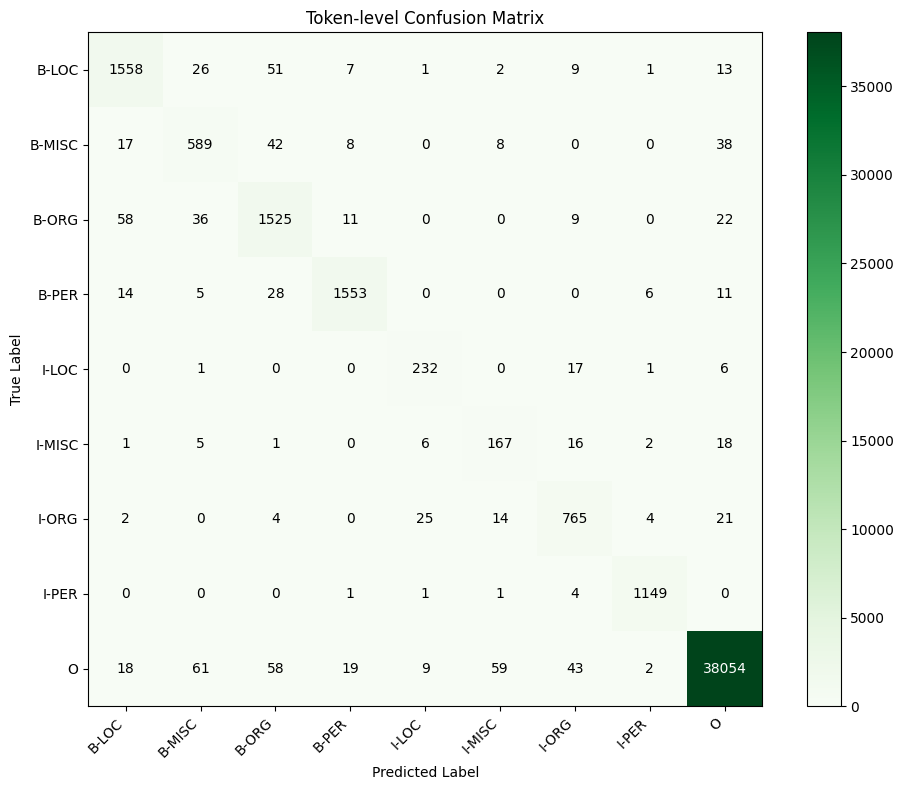

In [133]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

# Sử dụng cmap="Greens" (hoặc đổi thành "YlGn", "BuGn")
im = ax.imshow(cm, cmap="Greens")

ax.set_xticks(range(len(label_list)))
ax.set_yticks(range(len(label_list)))

ax.set_xticklabels(label_list)
ax.set_yticklabels(label_list)

plt.xticks(rotation=45, ha="right") # Căn phải nhãn trục X để đẹp hơn khi xoay

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_title("Token-level Confusion Matrix")

# Tự động đổi màu chữ: trắng nếu nền đậm, đen nếu nền nhạt
thresh = cm.max() / 2.
for i in range(len(label_list)):
    for j in range(len(label_list)):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > thresh else "black"
        )

fig.colorbar(im, ax=ax)

plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [85]:
experiment4_df = pd.concat(
    [
        baseline_type_df,
        transformer_type_df
    ],
    ignore_index=True
)

experiment4_df

,Model,Entity,TP,FP,FN,Precision,Recall,F1
0,Baseline,LOC,1338,374,330,0.781542,0.802158,0.791716
1,Baseline,ORG,1083,701,578,0.607063,0.652017,0.628737
2,Baseline,PER,1270,644,347,0.663532,0.785405,0.719343
3,Baseline,MISC,534,214,168,0.713904,0.760684,0.736552
4,Pretrained Transformer,PER,1551,53,66,0.966958,0.959184,0.963055
5,Pretrained Transformer,LOC,1551,124,117,0.925970,0.929856,0.927909
6,Pretrained Transformer,MISC,577,182,125,0.760211,0.821937,0.789870
7,Pretrained Transformer,ORG,1501,224,160,0.870145,0.903672,0.886592


In [86]:
experiment4_report = experiment4_df[
    [
        "Model",
        "Entity",
        "Precision",
        "Recall",
        "F1"
    ]
]

experiment4_report

,Model,Entity,Precision,Recall,F1
0,Baseline,LOC,0.781542,0.802158,0.791716
1,Baseline,ORG,0.607063,0.652017,0.628737
2,Baseline,PER,0.663532,0.785405,0.719343
3,Baseline,MISC,0.713904,0.760684,0.736552
4,Pretrained Transformer,PER,0.966958,0.959184,0.963055
5,Pretrained Transformer,LOC,0.925970,0.929856,0.927909
6,Pretrained Transformer,MISC,0.760211,0.821937,0.789870
7,Pretrained Transformer,ORG,0.870145,0.903672,0.886592


## Câu hỏi: Vì sao performance giữa các loại entity có thể khác nhau?
| Yếu tố | Giải thích |
|---|---|
| Số lượng training examples | Loại thực thể có nhiều ví dụ trong training set thường giúp mô hình học được các patterns tốt hơn. Những loại ít dữ liệu có thể khó nhận diện hơn. |
| Lexical patterns | Một số thực thể có các từ hoặc cấu trúc đặc trưng. Ví dụ, tên tổ chức có thể chứa `University`, `Company`, `Inc.`. |
| Ambiguity | Một từ có thể đại diện cho nhiều loại thực thể hoặc không phải thực thể tùy ngữ cảnh. |
| Context | Các từ xung quanh cung cấp thông tin giúp xác định loại thực thể. |
| Entity boundary | Một thực thể có thể gồm nhiều từ. Mô hình có thể nhận diện sai phạm vi, ví dụ chỉ nhận diện một phần tên tổ chức. |
| Domain | Cùng một loại thực thể nhưng vocabulary và cách sử dụng có thể khác nhau giữa tin tức, khoa học, thể thao và tài chính. |

# 22. Experiment 5 — Entity Length

In [87]:
def entity_length_bucket(length):
    if length == 1:
        return "1"
    elif length == 2:
        return "2"
    elif length == 3:
        return "3"
    else:
        return "4+"

In [88]:
def entity_length_evaluation(y_true, y_pred):
    buckets = ["1", "2", "3", "4+"]

    stats = {
        bucket: {
            "TP": 0,
            "FP": 0,
            "FN": 0
        }
        for bucket in buckets
    }

    for true_labels, pred_labels in zip(
        y_true,
        y_pred
    ):
        true_entities = set(
            extract_entities(true_labels)
        )

        pred_entities = set(
            extract_entities(pred_labels)
        )

        matched = true_entities & pred_entities
        wrong = pred_entities - true_entities
        missing = true_entities - pred_entities

        for start, end, _ in matched:
            length = end - start
            bucket = entity_length_bucket(length)
            stats[bucket]["TP"] += 1

        for start, end, _ in wrong:
            length = end - start
            bucket = entity_length_bucket(length)
            stats[bucket]["FP"] += 1

        for start, end, _ in missing:
            length = end - start
            bucket = entity_length_bucket(length)
            stats[bucket]["FN"] += 1

    results = []

    for bucket in buckets:
        tp = stats[bucket]["TP"]
        fp = stats[bucket]["FP"]
        fn = stats[bucket]["FN"]

        precision = (
            tp / (tp + fp)
            if tp + fp > 0
            else 0
        )

        recall = (
            tp / (tp + fn)
            if tp + fn > 0
            else 0
        )

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0
            else 0
        )

        results.append({
            "Entity Length": bucket,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

    return pd.DataFrame(results)

In [89]:
baseline_length_results = entity_length_evaluation(
    y_true_test,
    y_pred_test
)

baseline_length_results

,Entity Length,TP,FP,FN,Precision,Recall,F1
0,1,2808,1707,766,0.621927,0.785674,0.694276
1,2,1305,192,471,0.871743,0.734797,0.797434
2,3,105,29,131,0.783582,0.444915,0.567568
3,4+,7,5,55,0.583333,0.112903,0.189189


In [90]:
transformer_length_results = entity_length_evaluation(
    y_true_transformer,
    y_pred_transformer
)

transformer_length_results

,Entity Length,TP,FP,FN,Precision,Recall,F1
0,1,3279,397,295,0.892002,0.917459,0.904552
1,2,1638,141,138,0.920742,0.922297,0.921519
2,3,209,33,27,0.863636,0.885593,0.874477
3,4+,54,12,8,0.818182,0.870968,0.843750


In [91]:
baseline_length_results["Model"] = "Baseline"

transformer_length_results["Model"] = (
    "Pretrained Transformer"
)

experiment5_df = pd.concat(
    [
        baseline_length_results,
        transformer_length_results
    ],
    ignore_index=True
)

experiment5_df

,Entity Length,TP,FP,FN,Precision,Recall,F1,Model
0,1,2808,1707,766,0.621927,0.785674,0.694276,Baseline
1,2,1305,192,471,0.871743,0.734797,0.797434,Baseline
2,3,105,29,131,0.783582,0.444915,0.567568,Baseline
3,4+,7,5,55,0.583333,0.112903,0.189189,Baseline
4,1,3279,397,295,0.892002,0.917459,0.904552,Pretrained Transformer
5,2,1638,141,138,0.920742,0.922297,0.921519,Pretrained Transformer
6,3,209,33,27,0.863636,0.885593,0.874477,Pretrained Transformer
7,4+,54,12,8,0.818182,0.870968,0.843750,Pretrained Transformer


In [92]:
experiment5_report = experiment5_df[
    [
        "Model",
        "Entity Length",
        "Precision",
        "Recall",
        "F1"
    ]
]

experiment5_report

,Model,Entity Length,Precision,Recall,F1
0,Baseline,1,0.621927,0.785674,0.694276
1,Baseline,2,0.871743,0.734797,0.797434
2,Baseline,3,0.783582,0.444915,0.567568
3,Baseline,4+,0.583333,0.112903,0.189189
4,Pretrained Transformer,1,0.892002,0.917459,0.904552
5,Pretrained Transformer,2,0.920742,0.922297,0.921519
6,Pretrained Transformer,3,0.863636,0.885593,0.874477
7,Pretrained Transformer,4+,0.818182,0.870968,0.843750


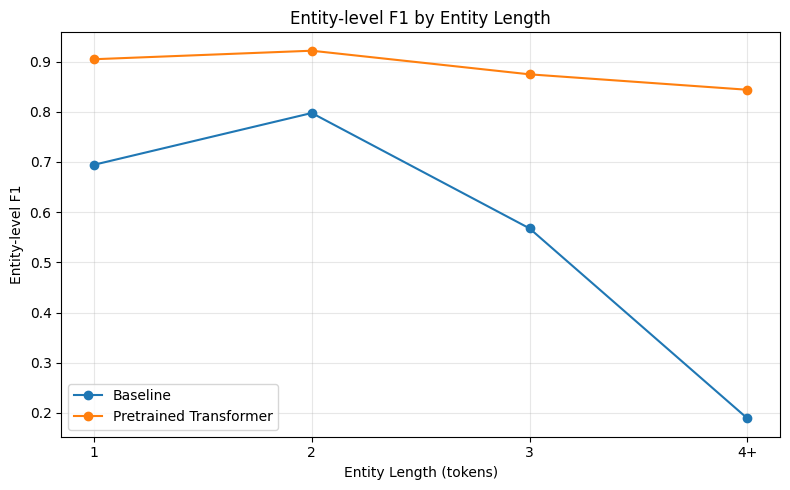

In [127]:
import matplotlib.pyplot as plt

length_order = ["1", "2", "3", "4+"]

plot_df = experiment5_df.copy()

plot_df["Entity Length"] = pd.Categorical(
    plot_df["Entity Length"],
    categories=length_order,
    ordered=True
)

plt.figure(figsize=(8, 5))

for model_name in plot_df["Model"].unique():
    model_data = (
        plot_df[plot_df["Model"] == model_name]
        .sort_values("Entity Length")
    )

    plt.plot(
        model_data["Entity Length"],
        model_data["F1"],
        marker="o",
        label=model_name
    )

plt.xlabel("Entity Length (tokens)")
plt.ylabel("Entity-level F1")
plt.title("Entity-level F1 by Entity Length")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "entity_length_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 23. Experiment 6 — Error Analysis

In [93]:
def collect_entity_errors(
    sentences,
    y_true,
    y_pred
):
    fp_rows = []
    fn_rows = []
    boundary_rows = []

    for sentence, true_labels, pred_labels in zip(
        sentences,
        y_true,
        y_pred
    ):
        words = [word for word, _ in sentence]

        true_entities = set(
            extract_entities(true_labels)
        )

        pred_entities = set(
            extract_entities(pred_labels)
        )

        missing = true_entities - pred_entities
        wrong = pred_entities - true_entities

        for entity in wrong:
            start, end, entity_type = entity

            fp_rows.append({
                "Text": " ".join(words),
                "Gold": entities_with_text(
                    words,
                    true_labels
                ),
                "Prediction": entities_with_text(
                    words,
                    pred_labels
                ),
                "Error entity": " ".join(
                    words[start:end]
                ),
                "Entity type": entity_type,
                "Error type": "False Positive"
            })

        for entity in missing:
            start, end, entity_type = entity

            fn_rows.append({
                "Text": " ".join(words),
                "Gold": entities_with_text(
                    words,
                    true_labels
                ),
                "Prediction": entities_with_text(
                    words,
                    pred_labels
                ),
                "Error entity": " ".join(
                    words[start:end]
                ),
                "Entity type": entity_type,
                "Error type": "False Negative"
            })

        # Boundary errors:
        # Gold and predicted entity share the same type
        # and overlap, but do not match exactly.

        for gold_entity in missing:
            gs, ge, gt = gold_entity

            for pred_entity in wrong:
                ps, pe, pt = pred_entity

                same_type = gt == pt
                overlap = max(gs, ps) < min(ge, pe)
                different_boundary = (
                    gs != ps or ge != pe
                )

                if (
                    same_type
                    and overlap
                    and different_boundary
                ):
                    boundary_rows.append({
                        "Text": " ".join(words),
                        "Gold entity": " ".join(
                            words[gs:ge]
                        ),
                        "Predicted entity": " ".join(
                            words[ps:pe]
                                        ),
                        "Entity type": gt,
                        "Error type": "Boundary Error"
                    })

    return fp_rows, fn_rows, boundary_rows

In [95]:
def entities_with_text(words, labels):
    entities = extract_entities(labels)

    results = []

    for start, end, entity_type in entities:
        results.append({
            "text": " ".join(words[start:end]),
            "type": entity_type,
            "start": start,
            "end": end
        })

    return results

In [98]:
fp_rows, fn_rows, boundary_rows = (
    collect_entity_errors(
        test_sentences,
        y_true_transformer,
        y_pred_transformer
    )
)

In [126]:
# 5 False Positives
fp_df = pd.DataFrame(fp_rows)

fp_df.head(5)

,Text,Gold,Prediction,Error entity,Entity type,Error type
0,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...","[{'text': 'JAPAN', 'type': 'LOC', 'start': 2, ...","[{'text': 'JAPAN', 'type': 'PER', 'start': 2, ...",LUCKY,PER,False Positive
1,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...","[{'text': 'JAPAN', 'type': 'LOC', 'start': 2, ...","[{'text': 'JAPAN', 'type': 'PER', 'start': 2, ...",JAPAN,PER,False Positive
2,Bitar pulled off fine saves whenever they did .,"[{'text': 'Bitar', 'type': 'PER', 'start': 0, ...","[{'text': 'Bitar', 'type': 'ORG', 'start': 0, ...",Bitar,ORG,False Positive
3,RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A ...,"[{'text': 'RUGBY UNION', 'type': 'ORG', 'start...","[{'text': 'RUGBY UNION', 'type': 'ORG', 'start...",CUTTITTA,ORG,False Positive
4,Cuttitta announced his retirement after the 19...,"[{'text': 'Cuttitta', 'type': 'PER', 'start': ...","[{'text': 'Cuttitta', 'type': 'PER', 'start': ...",World Cup,MISC,False Positive


In [100]:
# 5 False Negatives
fn_df = pd.DataFrame(fn_rows)

fn_df.head(5)

,Text,Gold,Prediction,Error entity,Entity type,Error type
0,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...","[{'text': 'JAPAN', 'type': 'LOC', 'start': 2, ...","[{'text': 'JAPAN', 'type': 'PER', 'start': 2, ...",JAPAN,LOC,False Negative
1,Bitar pulled off fine saves whenever they did .,"[{'text': 'Bitar', 'type': 'PER', 'start': 0, ...","[{'text': 'Bitar', 'type': 'ORG', 'start': 0, ...",Bitar,PER,False Negative
2,RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A ...,"[{'text': 'RUGBY UNION', 'type': 'ORG', 'start...","[{'text': 'RUGBY UNION', 'type': 'ORG', 'start...",CUTTITTA,PER,False Negative
3,RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A ...,"[{'text': 'RUGBY UNION', 'type': 'ORG', 'start...","[{'text': 'RUGBY UNION', 'type': 'ORG', 'start...",ITALY,LOC,False Negative
4,Cuttitta announced his retirement after the 19...,"[{'text': 'Cuttitta', 'type': 'PER', 'start': ...","[{'text': 'Cuttitta', 'type': 'PER', 'start': ...",1995 World Cup,MISC,False Negative


In [101]:
# 5 Boundary Errors
boundary_df = pd.DataFrame(boundary_rows)

boundary_df.head(5)

,Text,Gold entity,Predicted entity,Entity type,Error type
0,Cuttitta announced his retirement after the 19...,1995 World Cup,World Cup,MISC,Boundary Error
1,FREESTYLE SKIING-WORLD CUP MOGUL RESULTS .,SKIING-WORLD CUP,CUP,MISC,Boundary Error
2,SOCCER - ASIAN CUP GROUP C RESULTS .,ASIAN CUP,ASIAN CUP GROUP C,MISC,Boundary Error
3,Result of an English F.A. Challenge,English F.A. Challenge,English,MISC,Boundary Error
4,Result of an English F.A. Challenge,English F.A. Challenge,F.A. Challenge,MISC,Boundary Error


In [102]:
def make_error_report(
    rows,
    error_type,
    limit=5
):
    selected = rows[:limit]

    report = []

    for row in selected:
        report.append({
            "Text": row["Text"],
            "Gold": row.get(
                "Gold",
                row.get("Gold entity")
            ),
            "Prediction": row.get(
                "Prediction",
                row.get("Predicted entity")
            ),
            "Error type": error_type,
            "Explanation": ""
        })

    return pd.DataFrame(report)

In [103]:
fp_report = make_error_report(
    fp_rows,
    "False Positive",
    5
)

fn_report = make_error_report(
    fn_rows,
    "False Negative",
    5
)

boundary_report = make_error_report(
    boundary_rows,
    "Boundary Error",
    5
)

In [104]:
experiment6_df = pd.concat(
    [
        fp_report,
        fn_report,
        boundary_report
    ],
    ignore_index=True
)

experiment6_df

,Text,Gold,Prediction,Error type,Explanation
0,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...","[{'text': 'JAPAN', 'type': 'LOC', 'start': 2, ...","[{'text': 'JAPAN', 'type': 'PER', 'start': 2, ...",False Positive,
1,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...","[{'text': 'JAPAN', 'type': 'LOC', 'start': 2, ...","[{'text': 'JAPAN', 'type': 'PER', 'start': 2, ...",False Positive,
2,Bitar pulled off fine saves whenever they did .,"[{'text': 'Bitar', 'type': 'PER', 'start': 0, ...","[{'text': 'Bitar', 'type': 'ORG', 'start': 0, ...",False Positive,
3,RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A ...,"[{'text': 'RUGBY UNION', 'type': 'ORG', 'start...","[{'text': 'RUGBY UNION', 'type': 'ORG', 'start...",False Positive,
4,Cuttitta announced his retirement after the 19...,"[{'text': 'Cuttitta', 'type': 'PER', 'start': ...","[{'text': 'Cuttitta', 'type': 'PER', 'start': ...",False Positive,
5,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...","[{'text': 'JAPAN', 'type': 'LOC', 'start': 2, ...","[{'text': 'JAPAN', 'type': 'PER', 'start': 2, ...",False Negative,
6,Bitar pulled off fine saves whenever they did .,"[{'text': 'Bitar', 'type': 'PER', 'start': 0, ...","[{'text': 'Bitar', 'type': 'ORG', 'start': 0, ...",False Negative,
7,RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A ...,"[{'text': 'RUGBY UNION', 'type': 'ORG', 'start...","[{'text': 'RUGBY UNION', 'type': 'ORG', 'start...",False Negative,
8,RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A ...,"[{'text': 'RUGBY UNION', 'type': 'ORG', 'start...","[{'text': 'RUGBY UNION', 'type': 'ORG', 'start...",False Negative,
9,Cuttitta announced his retirement after the 19...,"[{'text': 'Cuttitta', 'type': 'PER', 'start': ...","[{'text': 'Cuttitta', 'type': 'PER', 'start': ...",False Negative,


# 24. Context Analysis

In [105]:
from collections import defaultdict

def find_context_ambiguity(sentences):
    occurrences = defaultdict(list)

    for sentence in sentences:
        words = [word for word, _ in sentence]
        labels = [label for _, label in sentence]

        for index, (word, label) in enumerate(
            sentence
        ):
            if label == "O":
                continue

            entity_type = label[2:]

            context_start = max(0, index - 3)
            context_end = min(
                len(words),
                index + 4
            )

            context = " ".join(
                words[context_start:context_end]
            )

            occurrences[word.lower()].append({
                "word": word,
                "entity_type": entity_type,
                "context": context,
                "label": label
            })

    results = []

    for surface_form, items in occurrences.items():
        entity_types = {
            item["entity_type"]
            for item in items
        }

        if len(entity_types) > 1:
            results.append({
                "surface_form": surface_form,
                "entity_types": entity_types,
                "occurrences": items
            })

    return results

In [106]:
context_ambiguity = find_context_ambiguity(
    test_sentences
)

len(context_ambiguity)

217

In [107]:
for item in context_ambiguity[:10]:
    print(
        "\nSurface form:",
        item["surface_form"]
    )

    print(
        "Entity types:",
        item["entity_types"]
    )

    for occurrence in item["occurrences"]:
        print(
            occurrence["entity_type"],
            "|",
            occurrence["context"]
        )


Surface form: japan
Entity types: {'ORG', 'LOC'}
LOC | SOCCER - JAPAN GET LUCKY WIN
LOC | Japan began the defence
LOC | six minutes allowed Japan to come from
LOC | Japan then laid siege
LOC | Japan coach Shu Kamo
LOC | Japan , co-hosts of
LOC | LATE GOALS GIVE JAPAN WIN OVER SYRIA
LOC | minutes gave holders Japan an uninspiring 2-1
LOC | Japan then laid siege
LOC | Japan started the second
LOC | Japan : 19 -
LOC | Tae Satoya ( Japan ) 23.75
LOC | Japan 2 Syria 1
LOC | Japan - Hassan Abbas
LOC | Japan 1 1 0
LOC | Japan 's authorities seen
LOC | Comments by Japan 's tight-lipped central
ORG | the Bank of Japan ( BOJ )
LOC | was quoted in Japan 's leading economic
LOC | 's view on Japan 's economy was
LOC | unfounded pessimism about Japan 's economy .
LOC | dollar terms , Japan was the only
LOC | ace 20/11/96 5,000 Japan
LOC | Emdldm 20/11/96 5,000 Japan
LOC | Ace 22/11/96 5,000 Japan
LOC | Japan 's Economic Planning
LOC | Japan NTT says hopes
LOC | operate in west Japan and the other
L

## Trả lời câu hỏi: Contextual representation có lợi thế
- ví dụ từ bank trong 2 câu: `I deposited money at the bank.` và `We sat on the bank of the river.`
- Static embedding truyền thống có thể sử dụng cùng một vector biểu diễn cho từ bank, mặc dù ý nghĩa trong hai câu khác nhau.
- Contextual representation tạo ra biểu diễn của từ dựa trên ngữ cảnh => Transformer có khả năng sử dụng context để phân biệt hai trường hợp này, thay vì chỉ dựa vào biểu diễn cố định của từ `Apple` hoặc `apple`.

# 25 Application

In [113]:
from transformers import pipeline

ner_pipeline = pipeline(
    "ner",
    model=trainer.model,
    tokenizer=tokenizer,
    aggregation_strategy="simple"
)

In [114]:
def extract_information(text, ner_pipeline):
    ner_output = ner_pipeline(text)

    result = {
        "PERSON": [],
        "ORGANIZATION": [],
        "LOCATION": [],
        "MISC": []
    }

    entity_mapping = {
        "PER": "PERSON",
        "ORG": "ORGANIZATION",
        "LOC": "LOCATION",
        "MISC": "MISC"
    }

    for entity in ner_output:
        entity_type = entity["entity_group"]
        mapped_type = entity_mapping.get(
            entity_type
        )

        if mapped_type is None:
            continue

        result[mapped_type].append(
            entity["word"]
        )

    return result

In [115]:
texts = [
    "Barack Obama visited Paris.",
    "Microsoft announced a new product.",
    "Apple is headquartered in California."
]

for text in texts:
    print("\nText:", text)

    result = extract_information(
        text,
        ner_pipeline
    )

    print(result)


Text: Barack Obama visited Paris.
{'PERSON': ['Barack Obama'], 'ORGANIZATION': [], 'LOCATION': ['Paris'], 'MISC': []}

Text: Microsoft announced a new product.
{'PERSON': [], 'ORGANIZATION': ['Microsoft'], 'LOCATION': [], 'MISC': []}

Text: Apple is headquartered in California.
{'PERSON': [], 'ORGANIZATION': ['Apple'], 'LOCATION': ['California'], 'MISC': []}


# 26. Mini Information Extraction Task

In [121]:
def extract_news_information(
    text,
    ner_pipeline
):
    ner_output = ner_pipeline(text)

    result = {
        "PERSON": [],
        "ORGANIZATION": [],
        "LOCATION": []
    }

    entity_mapping = {
        "PER": "PERSON",
        "ORG": "ORGANIZATION",
        "LOC": "LOCATION"
    }

    for entity in ner_output:
        entity_type = entity["entity_group"]

        mapped_type = entity_mapping.get(
            entity_type
        )

        if mapped_type is None:
            continue

        result[mapped_type].append(
            entity["word"]
        )

    return result

In [122]:
news_articles = [
    "Barack Obama visited Paris.",
    "Microsoft announced a new product.",
    "Apple is headquartered in California.",
    "The United Nations held a meeting in New York."
]

In [123]:
news_results = []

for text in news_articles:
    result = extract_news_information(
        text,
        ner_pipeline
    )

    news_results.append({
        "Text": text,
        "Entities": result
    })

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


In [124]:
news_ie_df = pd.DataFrame(
    news_results
)

news_ie_df

,Text,Entities
0,Barack Obama visited Paris.,"{'PERSON': ['Barack Obama'], 'ORGANIZATION': [..."
1,Microsoft announced a new product.,"{'PERSON': [], 'ORGANIZATION': ['Microsoft'], ..."
2,Apple is headquartered in California.,"{'PERSON': [], 'ORGANIZATION': ['Apple'], 'LOC..."
3,The United Nations held a meeting in New York.,"{'PERSON': [], 'ORGANIZATION': ['United Nation..."
